# Laboratorio Redes Convolucionales (PyTorch)

# 1. Introducción a la librería PyTorch

PyTorch es una librería de código abierto para la creación y entrenamiento de modelos de redes neuronales artificiales, desarrollada originalmente por el equipo de Facebook AI Research (hoy Meta AI) y liberada en 2016. Se ha convertido en una de las herramientas más utilizadas en investigación y en la industria del aprendizaje profundo gracias a su interfaz en Python, su cercanía a la sintaxis y estructuras de datos habituales de NumPy, y su enfoque de "definición sobre la marcha" (*define-by-run*), en el que el grafo de cómputo se construye dinámicamente a medida que se ejecuta el código. Esta última característica facilita la depuración y hace que el comportamiento del modelo sea más transparente para quien lo programa. La documentación de la librería se puede consultar en https://pytorch.org/docs/stable/index.html.

In [1]:
# Celda con la importación de librerías

import torch                       # Importar PyTorch
import torch.nn as nn              # Módulo con las capas y bloques para construir redes neuronales
import torch.optim as optim        # Módulo con los algoritmos de optimización
import torch.nn.functional as F    # Funciones auxiliares (activaciones, codificación one-hot, etc.)

from collections import OrderedDict # Permite nombrar las capas al construir un modelo secuencial

import numpy as np                 # Librería para trabajar con datos matriciales

import matplotlib.pyplot as plt    # Librería para gráficas y visualización

In [2]:
# Establecer la semilla para NumPy
np.random.seed(42)

# Establecer la semilla para el generador de PyTorch, tanto en CPU como en GPU
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

# Dispositivo de cómputo: se usa GPU si está disponible, de lo contrario CPU.
# A diferencia de Keras, en PyTorch se debe mover explícitamente tanto el modelo
# como los datos al dispositivo sobre el cual se quiere hacer el cómputo.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Usando dispositivo: {device}')

Usando dispositivo: cpu


## 1.1 Construcción de modelos neuronales

PyTorch permite la creación de una variedad de modelos neuronales, que incluyen perceptrones multicapa (MLP), redes neuronales convolucionales (CNN), redes neuronales recurrentes (RNN) y modelos generativos adversarios (GAN), entre otros. Para construir estos modelos, la librería ofrece el módulo `torch.nn`, que agrupa una colección diversa de capas, cada una con una función específica. Por ejemplo, las capas completamente conectadas `Linear` son utilizadas en redes densas, mientras que las capas convolucionales `Conv2d` permiten configurar capas de convolución. Los modelos se pueden definir de manera secuencial apilando capas con `nn.Sequential`, de forma similar a como se hace en Keras, o de manera más flexible definiendo una clase propia que herede de `nn.Module`. En las siguientes secciones exploraremos cómo construir varios tipos de modelos neuronales con `nn.Sequential`, centrándonos en particular en los modelos convolucionales.

A diferencia de Keras, PyTorch no incluye de fábrica métodos como `.summary()` o `plot_model()` para inspeccionar la arquitectura de un modelo; ese tipo de utilidades suelen dejarse a librerías externas (por ejemplo `torchinfo` o `torchviz`) o implementarse a la medida. Para mantener este laboratorio autocontenido, a continuación definimos dos funciones propias, `resumen_modelo` y `visualizar_modelo`, que replican el comportamiento de `model.summary()` y `plot_model()` para los modelos secuenciales que construiremos.

In [3]:
def resumen_modelo(modelo, input_shape):
    """
    Imprime un resumen del modelo, al estilo de Keras: para cada capa de nivel
    superior muestra su tipo, la forma de salida y su número de parámetros
    entrenables.

    Parámetros de entrada:
    modelo = modelo de PyTorch construido con nn.Sequential
    input_shape = forma de una instancia de entrada, sin incluir la dimensión de lote (batch)

    Parámetros de salida:
    Impresión en pantalla con el resumen del modelo.
    """
    parametros = list(modelo.parameters())
    dispositivo = parametros[0].device if parametros else 'cpu'
    entrada = torch.zeros(1, *input_shape, device=dispositivo)

    filas = []
    total_parametros = 0
    salida = entrada
    with torch.no_grad():
        for nombre, capa in modelo.named_children():
            salida = capa(salida)
            n_parametros = sum(p.numel() for p in capa.parameters())
            total_parametros += n_parametros
            filas.append((f'{nombre} ({capa.__class__.__name__})', tuple(salida.shape), n_parametros))

    ancho_nombre = max(len(f[0]) for f in filas) + 2
    print('_' * 65)
    print(f"{'Capa (tipo)':<{ancho_nombre}}{'Forma de salida':<22}{'Parámetros':>10}")
    print('=' * 65)
    for nombre, forma, n_parametros in filas:
        print(f"{nombre:<{ancho_nombre}}{str(forma):<22}{n_parametros:>10,}")
    print('=' * 65)
    print(f'Total de parámetros: {total_parametros:,}')
    print('_' * 65)

In [4]:
def visualizar_modelo(modelo, input_shape, nombre_archivo='model.png'):
    """
    Genera un diagrama simple de bloques apilados que representa la arquitectura
    del modelo, análogo a plot_model de Keras, y lo guarda como imagen.

    Parámetros de entrada:
    modelo = modelo de PyTorch construido con nn.Sequential
    input_shape = forma de una instancia de entrada, sin incluir la dimensión de lote (batch)
    nombre_archivo = nombre del archivo de imagen donde se guarda el diagrama

    Parámetros de salida:
    Gráfica con el diagrama de bloques del modelo.
    """
    parametros = list(modelo.parameters())
    dispositivo = parametros[0].device if parametros else 'cpu'
    entrada = torch.zeros(1, *input_shape, device=dispositivo)

    bloques = [('Entrada', tuple(entrada.shape))]
    salida = entrada
    with torch.no_grad():
        for nombre, capa in modelo.named_children():
            salida = capa(salida)
            bloques.append((capa.__class__.__name__, tuple(salida.shape)))

    fig, ax = plt.subplots(figsize=(4, 1.4 * len(bloques)))
    for i, (etiqueta, forma) in enumerate(bloques):
        y = len(bloques) - i
        ax.add_patch(plt.Rectangle((0, y - 0.4), 3, 0.8, facecolor='#5a2ff4', alpha=0.15, edgecolor='#5a2ff4'))
        ax.text(1.5, y, f'{etiqueta}\n{forma}', ha='center', va='center', fontsize=9)
        if i > 0:
            ax.annotate('', xy=(1.5, y + 0.4), xytext=(1.5, y + 0.6),
                        arrowprops=dict(arrowstyle='->', color='#5a2ff4'))
    ax.set_xlim(-0.5, 3.5)
    ax.set_ylim(0, len(bloques) + 1)
    ax.axis('off')
    plt.tight_layout()
    plt.savefig(nombre_archivo, dpi=150)
    plt.show()

Una vez definidas estas utilidades, estamos listos para comenzar a construir nuestros modelos neuronales. En PyTorch, la construcción de un modelo secuencial es un proceso estructurado y flexible: se inicializa un contenedor con la clase `nn.Sequential()` y se le pasan, en orden, las capas que lo componen. Cuando se desea asignar un nombre a cada capa (equivalente al atributo `name` de las capas en Keras), se puede envolver la lista de capas en un `OrderedDict`.

A continuación exploraremos algunos ejemplos de modelos neuronales. Para cada uno de ellos, proporcionaremos un resumen de su arquitectura y generaremos un diagrama que visualiza su estructura. Esta visualización nos ayudará a comprender mejor cómo se construyen y conectan las capas, además de establecer el número de parámetros que se ajustarán durante el proceso de entrenamiento.

In [5]:
"""
Creación de un modelo neuronal completamente conectado para una entrada de dimensión 500,
y para resolver una tarea de clasificación para un problema de tres clases. El modelo que
se construye solo tiene una capa oculta.
"""

# El modelo se construye apilando capas dentro de nn.Sequential.
# A diferencia de Keras, en PyTorch no existe una capa de entrada explícita ni una
# capa de salida "especial": simplemente se apilan las capas necesarias y, cuando
# hace falta, se añaden las funciones de activación como capas independientes.
modelo = nn.Sequential(
    # Capa completamente conectada: se debe indicar tanto el número de neuronas de
    # entrada (500, la dimensión de nuestros datos) como el de salida (128), y luego
    # se agrega la función de activación ReLU como una capa aparte.
    nn.Linear(500, 128),
    nn.ReLU(),

    # Capa de salida: al ser un problema de clasificación con tres clases se usan
    # tres neuronas de salida y activación softmax.
    nn.Linear(128, 3),
    nn.Softmax(dim=1),
).to(device)

In [6]:
# La función resumen_modelo permite visualizar un resumen del modelo: en este resumen
# se indican la cantidad de parámetros del modelo, el tipo de capa y la dimensión de
# salida de cada capa.
resumen_modelo(modelo, input_shape=(500,))

_________________________________________________________________
Capa (tipo)  Forma de salida       Parámetros
0 (Linear)   (1, 128)                  64,128
1 (ReLU)     (1, 128)                       0
2 (Linear)   (1, 3)                       387
3 (Softmax)  (1, 3)                         0
Total de parámetros: 64,515
_________________________________________________________________


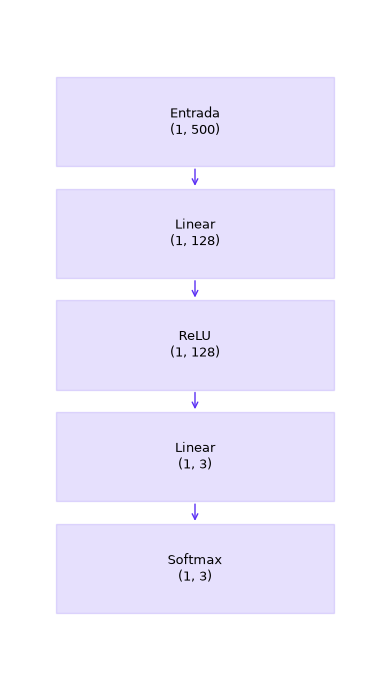

In [7]:
# Para visualizar la estructura del modelo se puede usar la función visualizar_modelo,
# definida previamente. Al visualizar el modelo también se guarda la imagen resultante.

# Parámetros de visualizar_modelo:
# modelo = modelo neuronal de PyTorch
# input_shape = dimensión de una instancia de entrada (sin la dimensión de lote)
# nombre_archivo = nombre del archivo de la imagen del diagrama
visualizar_modelo(modelo, input_shape=(500,), nombre_archivo='model.png')

In [8]:
"""
Creación de un modelo neuronal completamente conectado para una entrada de dimensión 2D,
de tamaño 20x20. Para resolver una tarea de clasificación binaria. El modelo que
se construye tiene 3 capas ocultas.
"""

# Dado que la entrada a este modelo es una forma de dimensión 2D, con tamaño 20x20 se
# inicia con una capa Flatten, o capa de aplanamiento; esta capa puede recibir este tipo
# de estructuras y convertirlas en formas 1D, en este caso una forma de dimensión 400.
modelo = nn.Sequential(
    nn.Flatten(),

    # Capas ocultas
    nn.Linear(400, 128), nn.ReLU(),  # Capa densa con 128 neuronas y activación ReLU
    nn.Linear(128, 64), nn.ReLU(),   # Capa densa con 64 neuronas y activación ReLU
    nn.Linear(64, 32), nn.ReLU(),    # Capa densa con 32 neuronas y activación ReLU

    # Capa de salida
    # Al ser un problema binario se considera una neurona y una activación tipo sigmoide
    nn.Linear(32, 1), nn.Sigmoid(),
).to(device)

In [9]:
# La función resumen_modelo permite visualizar un resumen del modelo
resumen_modelo(modelo, input_shape=(20, 20))

_________________________________________________________________
Capa (tipo)  Forma de salida       Parámetros
0 (Flatten)  (1, 400)                       0
1 (Linear)   (1, 128)                  51,328
2 (ReLU)     (1, 128)                       0
3 (Linear)   (1, 64)                    8,256
4 (ReLU)     (1, 64)                        0
5 (Linear)   (1, 32)                    2,080
6 (ReLU)     (1, 32)                        0
7 (Linear)   (1, 1)                        33
8 (Sigmoid)  (1, 1)                         0
Total de parámetros: 61,697
_________________________________________________________________


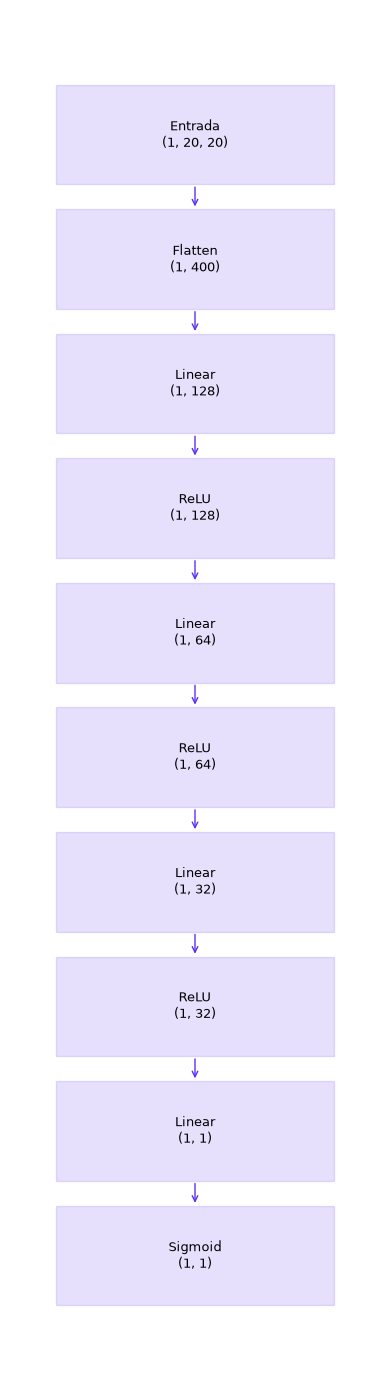

In [10]:
# Para visualizar el modelo usando visualizar_modelo
visualizar_modelo(modelo, input_shape=(20, 20), nombre_archivo='model.png')

In [11]:
"""
Las redes neuronales también pueden utilizarse para problemas de regresión; en este caso
se presenta un ejemplo de una estructura. En este apartado se crea un modelo neuronal
completamente conectado para una entrada de dimensión 2D de tamaño 10x10, para resolver
una tarea de regresión. El modelo que se construye tiene 2 capas ocultas y como función
de activación en la capa de salida se incluye la función lineal (es decir, no se aplica
ninguna función de activación).
"""

# En PyTorch los módulos no tienen un atributo de "nombre" incorporado como en Keras;
# en su lugar, se puede asignar cualquier atributo propio al objeto, como se hace aquí
# con el atributo nombre, o simplemente usar el nombre de la variable de Python.
# A las capas también se les puede asignar nombres, envolviendo la lista de capas en un
# OrderedDict; esto puede ser útil para identificarlas más fácilmente en el resumen.
modelo = nn.Sequential(OrderedDict([
    ('Aplanamiento', nn.Flatten()),

    ('Densa_1', nn.Linear(100, 64)),
    ('Activacion_1', nn.ReLU()),

    ('Densa_2', nn.Linear(64, 32)),
    ('Activacion_2', nn.ReLU()),

    # Capa de salida con función de activación lineal para regresión: nn.Identity()
    # deja pasar el valor sin transformarlo, equivalente a activation='linear' en Keras.
    ('Salida', nn.Linear(32, 1)),
])).to(device)
modelo.nombre = 'Modelo de regresión' 

In [12]:
# La función resumen_modelo permite visualizar un resumen del modelo; como en este
# modelo se fijaron los nombres de las capas, estos se pueden observar en el resumen.
print(f'Modelo: {modelo.nombre}')
resumen_modelo(modelo, input_shape=(10, 10))

Modelo: Modelo de regresión
_________________________________________________________________
Capa (tipo)             Forma de salida       Parámetros
Aplanamiento (Flatten)  (1, 100)                       0
Densa_1 (Linear)        (1, 64)                    6,464
Activacion_1 (ReLU)     (1, 64)                        0
Densa_2 (Linear)        (1, 32)                    2,080
Activacion_2 (ReLU)     (1, 32)                        0
Salida (Linear)         (1, 1)                        33
Total de parámetros: 8,577
_________________________________________________________________


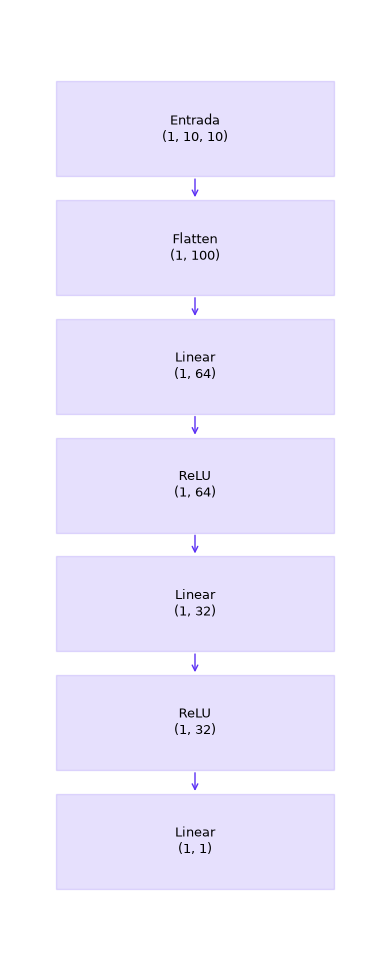

In [13]:
# Para visualizar el modelo usando visualizar_modelo
visualizar_modelo(modelo, input_shape=(10, 10), nombre_archivo='model.png')

En PyTorch también es posible la construcción de modelos neuronales convolucionales, ideales para tareas de visión por computadora y procesamiento de imágenes. Para lograr esto, la librería proporciona capas específicas denominadas `Conv2d`. En este tipo de capas se determina el número de canales de entrada, el número de filtros (canales de salida), la dimensión del kernel y, de forma independiente, la función de activación. Para complementar la acción de las capas de convolución y disminuir la dimensión, también se tienen capas de *pooling*; entre estas se destaca `MaxPool2d`, la cual utiliza la estrategia de tomar el valor máximo en una ventana específica, para esta capa se debe fijar la dimensión de la ventana. A diferencia de Keras, en PyTorch las capas convolucionales siguen la convención "canales primero" (`N, C, H, W`) en lugar de "canales al final" (`N, H, W, C`), y se debe indicar explícitamente el número de canales de entrada de cada capa `Conv2d`. A continuación exploraremos cómo utilizar estas capas para construir modelos neuronales convolucionales.

In [14]:
"""
En este apartado se crea un modelo neuronal para clasificación con 10 clases.
Este modelo se diseña con capas convolucionales para una entrada de dimensión 2D de tamaño
100x100 con tres canales; estas entradas pueden representar imágenes, donde la dimensión
serán los píxeles y los canales el color (en general las imágenes a color tienen 3 canales:
rojo, verde y azul). El siguiente modelo se construye con 2 capas convolucionales, cada una
seguida de una capa de pooling, y con una salida de 10 neuronas.
"""

modelo = nn.Sequential(
    # Capas de convolución
    # En la primera capa convolucional se utilizan 32 filtros con un kernel de dimensión
    # 3x3; esto significa que nuestra entrada, la cual se puede pensar como 3 matrices de
    # 100x100, luego de pasar por la capa de convolución tendrá 32 canales.
    # En cada filtro se usa un kernel de 3x3, esto quiere decir que se necesitan 9
    # parámetros por determinar en cada filtro. Al ser 32 filtros y 3 canales de entrada,
    # se requieren 32*9*3 = 864 parámetros; además se deben considerar los sesgos, uno por
    # cada filtro (32 en total). De modo que el tamaño total de los parámetros en la capa
    # de convolución es de 32*9*3 + 32 = 896.
    # Dado que no se incluyó ninguna técnica de relleno (padding, el valor por defecto en
    # PyTorch es 0, equivalente a padding='valid' en Keras) se elimina una fila arriba y
    # una abajo, y lo mismo sucede con las columnas. Por esta razón la dimensión de salida
    # es 98x98x32.
    nn.Conv2d(3, 32, kernel_size=3), nn.ReLU(),

    # Capa de pooling
    # Para disminuir la dimensión de los datos se complementa usando una capa de MaxPool2d;
    # la capa requiere la dimensión de la ventana sobre la cual se hará la reducción. Al
    # elegir una ventana de 2x2 entonces la dimensión de salida será 49x49x32. Esta capa
    # solo realiza una operación, no requiere parámetros de entrenamiento.
    nn.MaxPool2d(2),

    # Capa de convolución
    # En la segunda capa convolucional se utilizarán 64 filtros y un kernel de 3x3, por lo
    # tanto la salida de esta capa será 47x47x64. El número de parámetros se calcula igual
    # que en el caso anterior, multiplicando la cantidad de canales de entrada (32) por el
    # número de filtros de la capa y por los parámetros del kernel: 32*64*3*3 = 18432, y se
    # suman los sesgos (uno por filtro, 64 en total), de modo que el número de parámetros
    # es 18432 + 64 = 18496.
    nn.Conv2d(32, 64, kernel_size=3), nn.ReLU(),

    # Capa de pooling
    # Esta capa se fija con dimensión 2x2, entonces reduce las dimensiones a la mitad
    # entera; las nuevas dimensiones serán 23x23x64.
    nn.MaxPool2d(2),

    # Ahora se ubica una capa de aplanamiento, la cual condensa en un solo vector 1D la
    # salida con dimensiones 23x23x64.
    nn.Flatten(),

    # Al final se añade una capa densa de 128 neuronas. A diferencia de Keras, en PyTorch
    # se debe indicar explícitamente la dimensión de entrada de la capa (23*23*64=33856).
    nn.Linear(23 * 23 * 64, 128), nn.ReLU(),

    # La capa de salida se fija con tantas neuronas como clases y función de activación
    # softmax.
    nn.Linear(128, 10), nn.Softmax(dim=1),
).to(device)

In [15]:
# Con la función resumen_modelo se puede revisar el número de parámetros en cada capa
# y las dimensiones.
resumen_modelo(modelo, input_shape=(3, 100, 100))

_________________________________________________________________
Capa (tipo)    Forma de salida       Parámetros
0 (Conv2d)     (1, 32, 98, 98)              896
1 (ReLU)       (1, 32, 98, 98)                0
2 (MaxPool2d)  (1, 32, 49, 49)                0
3 (Conv2d)     (1, 64, 47, 47)           18,496
4 (ReLU)       (1, 64, 47, 47)                0
5 (MaxPool2d)  (1, 64, 23, 23)                0
6 (Flatten)    (1, 33856)                     0
7 (Linear)     (1, 128)               4,333,696
8 (ReLU)       (1, 128)                       0
9 (Linear)     (1, 10)                    1,290
10 (Softmax)   (1, 10)                        0
Total de parámetros: 4,354,378
_________________________________________________________________


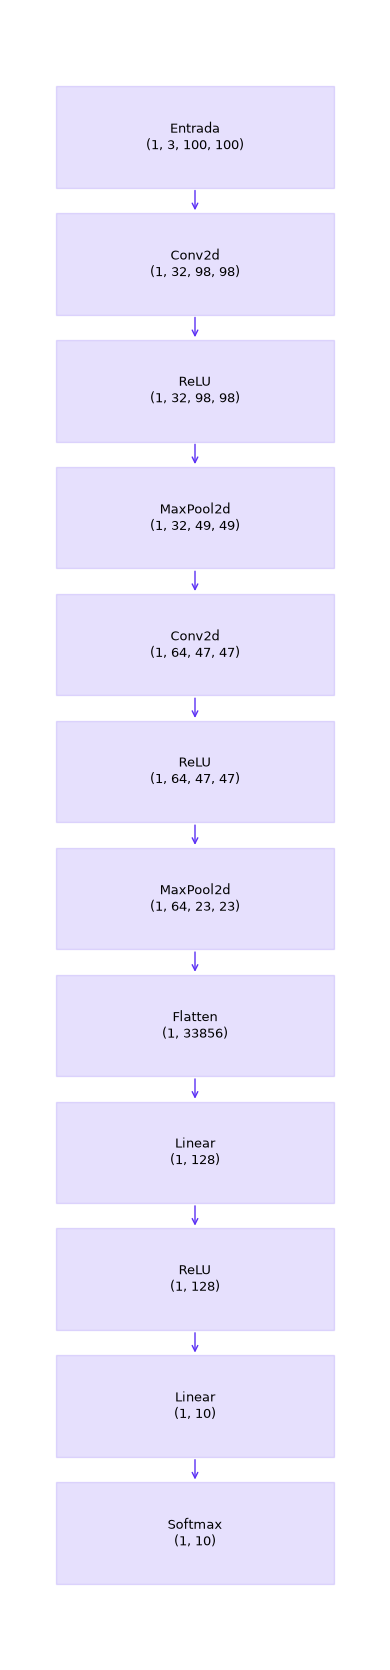

In [16]:
# Para visualizar el modelo usando visualizar_modelo
visualizar_modelo(modelo, input_shape=(3, 100, 100), nombre_archivo='model.png')

En las capas convolucionales también se puede agregar condiciones de *padding* y *strides*. En PyTorch, al fijar `padding='same'` se agrega relleno a la entrada para que la salida tenga la misma altura y anchura que la entrada, siempre que el desplazamiento (*stride*) sea igual a 1; el relleno garantiza que no perdamos información en los bordes de la imagen durante la convolución. Los *strides* indican cuántos píxeles se desplaza el filtro en cada paso. A diferencia de Keras, PyTorch no admite `padding='same'` cuando el *stride* es distinto de 1, por lo que en ese caso el relleno equivalente debe calcularse y aplicarse manualmente con una capa `ZeroPad2d`, como se muestra en el siguiente ejemplo.

In [17]:
"""
En este apartado se crea un modelo neuronal para clasificación con 10 clases.
Este modelo se diseña con una capa convolucional para una entrada de dimensión 2D de
tamaño 100x100 con tres canales. El siguiente modelo se construye con 1 capa
convolucional, que incluye padding y stride. La salida del modelo son 10 neuronas y
función de activación softmax.
"""

# Keras, con padding='same' y strides=(2, 2) sobre una entrada de 100x100, agrega un
# relleno asimétrico de un píxel (abajo y a la derecha) para producir una salida de
# 50x50. En PyTorch replicamos ese mismo relleno de forma explícita con ZeroPad2d,
# ya que padding='same' no admite strides distintos de 1.
modelo = nn.Sequential(
    nn.ZeroPad2d((0, 1, 0, 1)),  # relleno: (izquierda, derecha, arriba, abajo)

    # Capa de convolución con stride=(2, 2), es decir, el filtro se desplaza dos
    # posiciones en filas y en columnas a la vez.
    nn.Conv2d(3, 32, kernel_size=3, stride=2), nn.ReLU(),

    # Capa de MaxPool2d
    nn.MaxPool2d(2),

    # Capa de aplanamiento
    nn.Flatten(),

    # Capa totalmente conectada
    nn.Linear(25 * 25 * 32, 64), nn.ReLU(),

    # Capa de salida
    nn.Linear(64, 10), nn.Softmax(dim=1),
).to(device)

In [18]:
resumen_modelo(modelo, input_shape=(3, 100, 100))

_________________________________________________________________
Capa (tipo)    Forma de salida       Parámetros
0 (ZeroPad2d)  (1, 3, 101, 101)               0
1 (Conv2d)     (1, 32, 50, 50)              896
2 (ReLU)       (1, 32, 50, 50)                0
3 (MaxPool2d)  (1, 32, 25, 25)                0
4 (Flatten)    (1, 20000)                     0
5 (Linear)     (1, 64)                1,280,064
6 (ReLU)       (1, 64)                        0
7 (Linear)     (1, 10)                      650
8 (Softmax)    (1, 10)                        0
Total de parámetros: 1,281,610
_________________________________________________________________


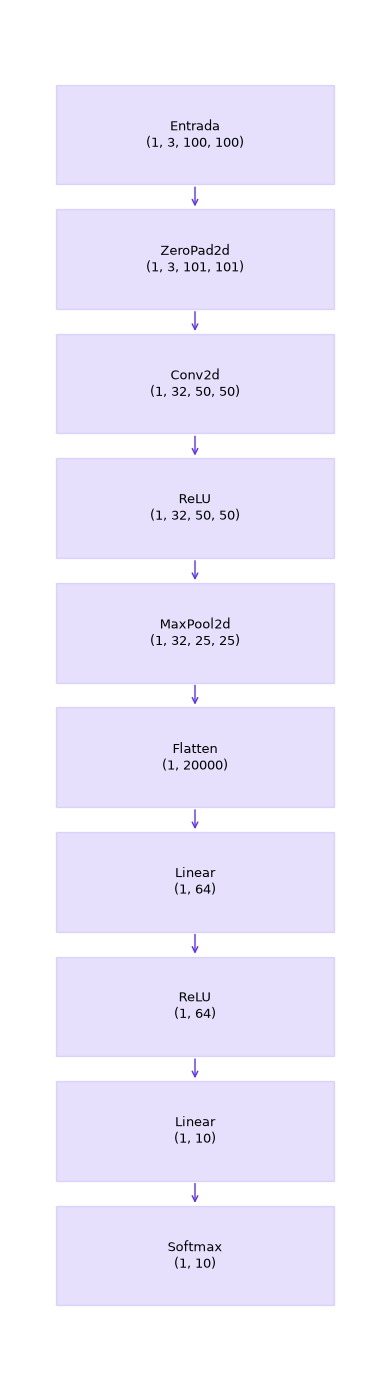

In [19]:
# Para visualizar el modelo usando visualizar_modelo
visualizar_modelo(modelo, input_shape=(3, 100, 100), nombre_archivo='model.png')

## 1.2 Configuración del entrenamiento del modelo neuronal

En la sección anterior construimos la arquitectura de nuestro modelo neuronal en PyTorch, definiendo las capas y la estructura de la red. En Keras, el siguiente paso sería "compilar" el modelo con un único método `.compile()`. PyTorch no tiene un paso de compilación equivalente (de hecho, desde la versión 2.0, `torch.compile` existe pero cumple un propósito distinto: optimizar la ejecución del grafo de cómputo, no configurar la función de pérdida ni el optimizador). En su lugar, en PyTorch se instancian por separado los objetos que se necesitarán durante el entrenamiento: la función de pérdida (o *criterio*), el optimizador —que se enlaza explícitamente a los parámetros del modelo— y, si se desean, funciones para calcular métricas. En las siguientes subsecciones revisamos cada uno de estos elementos.

### Función de pérdida

En PyTorch, puedes seleccionar la función de pérdida apropiada según el tipo de problema que estés resolviendo; estas clases viven en el módulo `torch.nn`. Por ejemplo, para problemas de clasificación multiclase la función de pérdida comúnmente utilizada es `CrossEntropyLoss`, mientras que para problemas de regresión se suele usar `MSELoss`. La elección de la función de pérdida depende de la naturaleza de tu tarea.

- `nn.MSELoss`: Error cuadrático medio, ideal para problemas de regresión (equivalente a `mean_squared_error` en Keras).
- `nn.BCELoss`: Entropía cruzada binaria, ideal para problemas de clasificación binaria (equivalente a `binary_crossentropy`); requiere que la capa de salida ya entregue probabilidades (por ejemplo, tras una `Sigmoid`).
- `nn.CrossEntropyLoss`: Entropía cruzada categórica, ideal para problemas de clasificación multiclase. A diferencia de Keras, esta función combina internamente `softmax` y la pérdida logarítmica, por lo que se aplica directamente sobre las salidas sin normalizar (*logits*) y espera las etiquetas como enteros de clase, no en formato one-hot (equivalente conceptualmente a `sparse_categorical_crossentropy`).
- `nn.NLLLoss`: Pérdida logarítmica negativa, se usa cuando ya se dispone de log-probabilidades (por ejemplo, a la salida de una capa `LogSoftmax`).

In [20]:
# Para instanciar una función de pérdida basta con llamar a la clase correspondiente
# del módulo torch.nn. En este caso se define el error cuadrático medio.
criterio = nn.MSELoss()

### Optimizadores

En el proceso de entrenamiento de redes neuronales, el método de retropropagación (*backpropagation*) es la base para ajustar los pesos del modelo a medida que aprende de los datos. Sin embargo, existen variaciones en la forma en que se implementa este proceso, y estas variaciones dan lugar a los optimizadores. PyTorch ofrece, en el módulo `torch.optim`, una amplia gama de optimizadores populares, como SGD (Descenso de Gradiente Estocástico), Adam, RMSprop, entre otros.

Todos estos optimizadores se fundamentan en la retropropagación; la metodología específica de cada uno se puede consultar en https://pytorch.org/docs/stable/optim.html. Para cada optimizador se pueden definir hiperparámetros adicionales, como la tasa de aprendizaje y otros ajustes específicos del optimizador. Estos hiperparámetros influyen en la velocidad y eficacia del proceso de entrenamiento y pueden ser sintonizados para optimizar el rendimiento del modelo. A diferencia de Keras, en PyTorch el optimizador se construye pasándole explícitamente los parámetros del modelo que debe actualizar (`modelo.parameters()`).

In [21]:
# Para establecer el optimizador se debe llamar a la clase, indicar los parámetros
# del modelo que actualizará y establecer sus hiperparámetros; aquí se detallan algunos
# ejemplos.

# Optimizador SGD: este optimizador permite establecer entre sus hiperparámetros la
# tasa de aprendizaje en el atributo lr.
mi_optimizador_SGD = optim.SGD(modelo.parameters(), lr=0.1)

# Optimizador Adam: este optimizador permite establecer entre sus hiperparámetros la
# tasa de aprendizaje en el atributo lr, y las constantes beta1 y beta2 (agrupadas en la
# tupla betas). En la documentación de la librería se puede consultar la rutina
# específica del optimizador y el efecto de estos hiperparámetros.
mi_optimizador_Adam = optim.Adam(modelo.parameters(), lr=0.001, betas=(0.9, 0.89))

# Optimizador RMSprop: este optimizador permite establecer entre sus hiperparámetros la
# tasa de aprendizaje en el atributo lr.
mi_optimizador_RMSprop = optim.RMSprop(modelo.parameters(), lr=0.001)

# Si algún optimizador quiere configurarse con sus valores por defecto, solo se llama a
# la clase pasando los parámetros del modelo, sin fijar los demás hiperparámetros.
mi_optimizador = optim.SGD(modelo.parameters())

In [22]:
# El criterio de pérdida y el optimizador construidos se usarán más adelante, dentro
# del ciclo de entrenamiento, para calcular el error y actualizar los pesos del modelo.
criterio = nn.CrossEntropyLoss()
optimizador = mi_optimizador

### Métricas

Las métricas son utilizadas para evaluar el rendimiento del modelo durante el entrenamiento y la evaluación. Puedes definir métricas que te ayuden a comprender cómo se desempeña el modelo en términos de exactitud, pérdida u otras estimaciones relevantes para la tarea específica. Estas métricas proporcionan información sobre el progreso del entrenamiento y la calidad de las predicciones. A diferencia de Keras, donde las métricas se declaran dentro de `.compile()` y se calculan automáticamente en cada época, en PyTorch no existe un mecanismo integrado de métricas: estas se calculan manualmente dentro del ciclo de entrenamiento (o, alternativamente, usando una librería especializada como `torchmetrics`). A continuación se definen un par de funciones sencillas para calcular la exactitud, la precisión y la exhaustividad (*recall*) a partir de las salidas del modelo.

In [23]:
def exactitud(salidas, etiquetas):
    """
    Calcula la exactitud (accuracy) de un lote de predicciones.
    Parámetros:
    salidas = tensor con las salidas del modelo (logits o probabilidades), de forma (N, clases)
    etiquetas = tensor con las etiquetas verdaderas como índices de clase, de forma (N,)
    Salida:
    Exactitud como un valor flotante entre 0 y 1.
    """
    predicciones = salidas.argmax(dim=1)
    return (predicciones == etiquetas).float().mean().item()


def precision_exhaustividad(salidas, etiquetas, num_clases):
    """
    Calcula la precisión y la exhaustividad (recall) promediadas entre clases
    (promedio macro) a partir de las salidas del modelo.
    Parámetros:
    salidas = tensor con las salidas del modelo (logits o probabilidades), de forma (N, clases)
    etiquetas = tensor con las etiquetas verdaderas como índices de clase, de forma (N,)
    num_clases = número de clases del problema
    Salida:
    Tupla (precisión, exhaustividad) promediada entre clases.
    """
    predicciones = salidas.argmax(dim=1)
    precisiones, exhaustividades = [], []
    for c in range(num_clases):
        verdaderos_positivos = ((predicciones == c) & (etiquetas == c)).sum().item()
        falsos_positivos = ((predicciones == c) & (etiquetas != c)).sum().item()
        falsos_negativos = ((predicciones != c) & (etiquetas == c)).sum().item()
        precisiones.append(verdaderos_positivos / (verdaderos_positivos + falsos_positivos)
                            if (verdaderos_positivos + falsos_positivos) > 0 else 0.0)
        exhaustividades.append(verdaderos_positivos / (verdaderos_positivos + falsos_negativos)
                                if (verdaderos_positivos + falsos_negativos) > 0 else 0.0)
    return float(np.mean(precisiones)), float(np.mean(exhaustividades))

# 2. Conjunto de datos MNIST

A continuación vamos a explorar el conjunto de datos MNIST, una base de datos icónica de imágenes que representa la escritura manual de dígitos del 0 al 9. El conjunto de datos MNIST es ampliamente utilizado en el campo del aprendizaje automático y la visión por computadora como referencia para tareas de clasificación. Utilizaremos este conjunto de datos para entrenar nuestros modelos convolucionales. El artículo original que describe el conjunto de datos MNIST se titula "Gradient-based learning applied to document recognition" (Aprendizaje basado en gradientes aplicado al reconocimiento de documentos), escrito por Yann LeCun, L. Bottou, Y. Bengio y P. Haffner en 1998. Para consultar más detalles de este conjunto de datos puedes visitar https://paperswithcode.com/dataset/mnist.

A través de `torchvision`, la librería de visión por computadora del ecosistema de PyTorch, tenemos acceso directo al conjunto de datos MNIST, una colección de 70,000 imágenes. De este conjunto, 60,000 imágenes se destinan al entrenamiento de modelos, mientras que las 10,000 restantes se reservan para pruebas y evaluación de rendimiento. Las imágenes tienen una dimensión de 28x28 píxeles y se presentan en un solo canal de color.

In [24]:
# Para importar el conjunto de datos se toma la clase datasets de torchvision, y para
# cargar los datos por lotes durante el entrenamiento usaremos DataLoader y TensorDataset.
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, TensorDataset

En tareas de clasificación multiclase, como el conjunto de datos MNIST, las etiquetas suelen presentarse como valores numéricos (0, 1, 2, ..., 9). En Keras, es común codificar estas etiquetas mediante *one-hot*, creando vectores de 10 posiciones donde cada posición representa la pertenencia a una clase específica, para poder usarlas junto con `categorical_crossentropy`. En PyTorch, la función `nn.CrossEntropyLoss` combina internamente `softmax` y la pérdida logarítmica, por lo que espera directamente las etiquetas como enteros de clase (no en formato one-hot); por esa razón, más adelante entrenaremos nuestro modelo usando las etiquetas originales. Aun así, a continuación mostramos cómo obtener la codificación one-hot con `torch.nn.functional.one_hot`, pues sigue siendo una representación útil en otros contextos (por ejemplo, al usar `MSELoss` o `BCELoss` sobre una salida de tipo probabilidad).

In [25]:
def cargar_datos():
    """
    Esta función carga al entorno de trabajo los datos de entrenamiento y prueba de MNIST,
    con sus etiquetas codificadas en one-hot.
    Parámetros de entrada:
    Ninguno (los datos se descargan, si es necesario, desde torchvision).
    Parámetros de salida:
    X_train = Conjunto de datos para entrenamiento, con forma (60000, 1, 28, 28)
    X_test = Conjunto de datos para prueba, con forma (10000, 1, 28, 28)
    y_train_onehot = Etiquetas del conjunto de entrenamiento codificadas en one-hot
    y_test_onehot = Etiquetas del conjunto de prueba codificadas en one-hot
    y_train = Etiqueta original del conjunto de entrenamiento (como índices de clase)
    y_test = Etiqueta original del conjunto de prueba (como índices de clase)
    """

    # Descarga (si hace falta) y carga los conjuntos de entrenamiento y prueba
    train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transforms.ToTensor())
    test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transforms.ToTensor())

    # Normalización de los valores de los píxeles de las imágenes, y se agrega la
    # dimensión del canal (PyTorch espera imágenes con forma canal-primero: N, C, H, W)
    X_train = train_dataset.data.float().div(255.0).unsqueeze(1)
    X_test = test_dataset.data.float().div(255.0).unsqueeze(1)

    y_train = train_dataset.targets
    y_test = test_dataset.targets

    # Codificación One-Hot para las etiquetas
    y_train_onehot = F.one_hot(y_train, num_classes=10).float()
    y_test_onehot = F.one_hot(y_test, num_classes=10).float()

    print('Conjunto de datos cargados')
    print(f'Tamaño imágenes de entrenamiento {tuple(X_train.shape)}')
    print(f'Tamaño imágenes de test {tuple(X_test.shape)}')
    print(f'Datos por cada etiqueta en X train {np.bincount(y_train.numpy())}')

    return X_train, X_test, y_train_onehot, y_test_onehot, y_train, y_test

In [26]:
# En esta línea de código se ejecuta la función de cargue de datos
X_train, X_test, y_train_onehot, y_test_onehot, y_train, y_test = cargar_datos()

Conjunto de datos cargados
Tamaño imágenes de entrenamiento (60000, 1, 28, 28)
Tamaño imágenes de test (10000, 1, 28, 28)
Datos por cada etiqueta en X train [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


In [27]:
def visualizar_instancias(X_datos, y_datos):
    """
    Esta función visualiza una instancia de cada categoría del conjunto MNIST
    Parámetros de entrada:
    X_datos = Instancias, con forma (N, 1, 28, 28)
    y_datos = Etiquetas, como índices de clase
    Parámetros de salida:
    Gráfica con la visualización de la imagen de cada instancia.
    """
    fig, ax = plt.subplots(nrows=2, ncols=5, sharex=True, sharey=True, figsize=(10, 5))
    ax = ax.flatten()
    for i in range(10):
        img = X_datos[y_datos == i][0, 0].numpy()
        ax[i].imshow(img, cmap='gist_yarg')
        ax[0].set_xticks([])
        ax[0].set_yticks([])
    return plt.show()

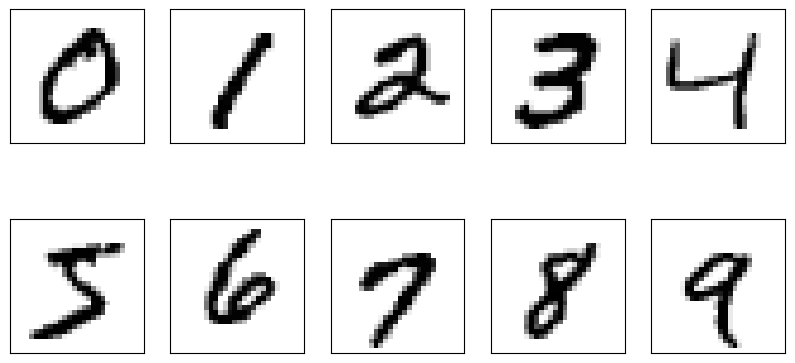

In [28]:
visualizar_instancias(X_train, y_train)

## 2.1 Modelo neuronal para clasificación MNIST

Para el conjunto de datos MNIST se construye un modelo neuronal convolucional mediante la función `crear_modelo(nombre)`. El modelo se configura y se entrena con los datos que se han separado previamente. Además, se muestran las gráficas del entrenamiento con las métricas seleccionadas y se efectúa la validación con el conjunto de prueba.

In [29]:
def crear_modelo(nombre):
    """
    Esta función construye un modelo neuronal convolucional para el problema de
    clasificación con MNIST. Este modelo se construye con dos capas convolucionales,
    cada una seguida de una capa de pooling.

    Parámetros:
    nombre = nombre del modelo

    Salida:
    modelo = modelo neuronal convolucional en PyTorch
    """
    modelo = nn.Sequential(OrderedDict([
        # Primera capa convolucional: kernel de 3x3, 16 filtros y padding='same' para
        # conservar la altura y anchura de la entrada (28x28).
        ('conv1', nn.Conv2d(1, 16, kernel_size=3, padding='same')),
        ('relu1', nn.ReLU()),
        # Capa de MaxPool2d
        ('pool1', nn.MaxPool2d(kernel_size=2)),

        # Segunda capa convolucional: kernel de 3x3 y 32 filtros
        ('conv2', nn.Conv2d(16, 32, kernel_size=3, padding='same')),
        ('relu2', nn.ReLU()),
        # Capa de MaxPool2d
        ('pool2', nn.MaxPool2d(kernel_size=4)),

        # Capa de aplanamiento
        ('flatten', nn.Flatten()),

        # Capa totalmente conectada con 100 neuronas
        ('densa', nn.Linear(3 * 3 * 32, 100)),
        ('relu3', nn.ReLU()),

        # Capa de salida
        ('salida', nn.Linear(100, 10)),
    ]))
    modelo.nombre = nombre

    return modelo

In [30]:
# Llamado a la función de crear modelo con parámetro el nombre
modelo = crear_modelo('ModeloClasificacionMNIST').to(device)

In [31]:
# Resumen de las dimensiones y parámetros del modelo
resumen_modelo(modelo, input_shape=(1, 28, 28))

_________________________________________________________________
Capa (tipo)        Forma de salida       Parámetros
conv1 (Conv2d)     (1, 16, 28, 28)              160
relu1 (ReLU)       (1, 16, 28, 28)                0
pool1 (MaxPool2d)  (1, 16, 14, 14)                0
conv2 (Conv2d)     (1, 32, 14, 14)            4,640
relu2 (ReLU)       (1, 32, 14, 14)                0
pool2 (MaxPool2d)  (1, 32, 3, 3)                  0
flatten (Flatten)  (1, 288)                       0
densa (Linear)     (1, 100)                  28,900
relu3 (ReLU)       (1, 100)                       0
salida (Linear)    (1, 10)                    1,010
Total de parámetros: 34,710
_________________________________________________________________


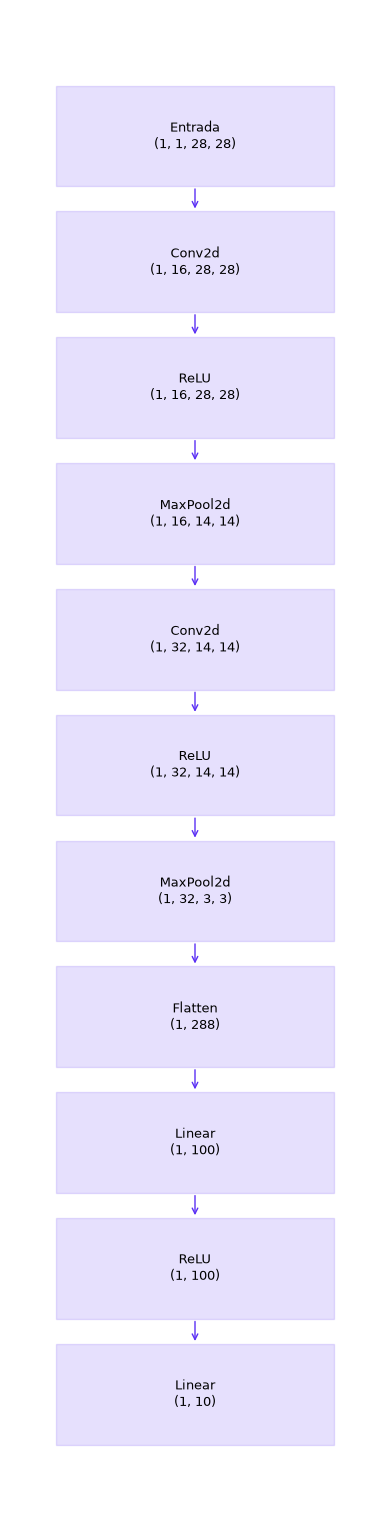

In [32]:
# Para visualizar el modelo usando visualizar_modelo
visualizar_modelo(modelo, input_shape=(1, 28, 28), nombre_archivo='model.png')

Una vez que hemos definido la arquitectura de nuestro modelo, el siguiente paso es configurar los elementos necesarios para el entrenamiento. Dado que estamos abordando un problema de clasificación multiclase, se utiliza la función de pérdida `nn.CrossEntropyLoss`, adecuada para este tipo de tareas y que, como se explicó antes, trabaja directamente con las etiquetas originales (no con la versión one-hot). Además, hemos optado por el optimizador `Adam`, y para evaluar el rendimiento del modelo usaremos la función `exactitud` definida previamente, tanto en el conjunto de entrenamiento como en el de validación.

In [33]:
# Configuración del entrenamiento
# criterio = nn.CrossEntropyLoss, entropía cruzada categórica (trabaja con logits y
#            etiquetas como índices de clase, sin necesidad de one-hot)
# optimizador = Adam, configurado con sus hiperparámetros por defecto
# la exactitud se calculará dentro del ciclo de entrenamiento con la función exactitud

criterio = nn.CrossEntropyLoss()
optimizador = optim.Adam(modelo.parameters())

## 2.2 Entrenamiento del modelo neuronal para MNIST

En Keras, el entrenamiento de un modelo se realiza con una única llamada al método `.fit()`. En PyTorch no existe un método equivalente: el ciclo de entrenamiento se escribe explícitamente, iterando sobre las épocas y, dentro de cada una, sobre los lotes (*mini-batches*) de datos de entrenamiento que entrega un `DataLoader`. En cada lote se calcula la salida del modelo, se compara con las etiquetas mediante la función de pérdida, se propaga el error hacia atrás (`loss.backward()`) y se actualizan los pesos (`optimizer.step()`). Al final de cada época se evalúa el modelo sobre el conjunto de validación, sin actualizar los pesos (`torch.no_grad()`), para poder monitorear su capacidad de generalización. La función `entrenar_modelo` que se define a continuación encapsula este ciclo y devuelve un diccionario `history` con la misma estructura que produce Keras en el atributo `history` del objeto que retorna `.fit()`.

In [34]:
def entrenar_modelo(modelo, criterio, optimizador, X_train, y_train, X_test, y_test,
                     epochs=15, batch_size=32, device=device):
    """
    Entrena el modelo replicando el comportamiento de model.fit en Keras: itera por
    épocas, recorre los datos de entrenamiento en lotes (mini-batches), calcula la
    pérdida y la exactitud, actualiza los pesos por retropropagación, y evalúa al
    final de cada época sobre el conjunto de validación.

    Parámetros:
    modelo = modelo de PyTorch a entrenar
    criterio = función de pérdida
    optimizador = optimizador ya enlazado a los parámetros del modelo
    X_train, y_train = datos y etiquetas de entrenamiento
    X_test, y_test = datos y etiquetas de validación
    epochs = número de épocas de entrenamiento
    batch_size = tamaño del lote
    device = dispositivo de cómputo (CPU o GPU)

    Salida:
    history = diccionario con las llaves 'loss', 'accuracy', 'val_loss' y 'val_accuracy',
              cada una asociada a una lista con el valor de la métrica en cada época.
    """
    dataset_entrenamiento = TensorDataset(X_train, y_train)
    cargador_entrenamiento = DataLoader(dataset_entrenamiento, batch_size=batch_size, shuffle=True)

    X_test_dev = X_test.to(device)
    y_test_dev = y_test.to(device)

    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}

    for epoca in range(epochs):
        modelo.train()
        perdida_epoca, aciertos_epoca, n_ejemplos = 0.0, 0, 0

        for X_lote, y_lote in cargador_entrenamiento:
            X_lote, y_lote = X_lote.to(device), y_lote.to(device)

            optimizador.zero_grad()
            salidas = modelo(X_lote)
            perdida = criterio(salidas, y_lote)
            perdida.backward()
            optimizador.step()

            perdida_epoca += perdida.item() * X_lote.size(0)
            aciertos_epoca += (salidas.argmax(dim=1) == y_lote).sum().item()
            n_ejemplos += X_lote.size(0)

        modelo.eval()
        with torch.no_grad():
            salidas_val = modelo(X_test_dev)
            perdida_val = criterio(salidas_val, y_test_dev).item()
            exactitud_val = exactitud(salidas_val, y_test_dev)

        history['loss'].append(perdida_epoca / n_ejemplos)
        history['accuracy'].append(aciertos_epoca / n_ejemplos)
        history['val_loss'].append(perdida_val)
        history['val_accuracy'].append(exactitud_val)

        print(f"Epoch {epoca + 1}/{epochs} - loss: {history['loss'][-1]:.4f} - "
              f"accuracy: {history['accuracy'][-1]:.4f} - val_loss: {history['val_loss'][-1]:.4f} - "
              f"val_accuracy: {history['val_accuracy'][-1]:.4f}")

    return history

In [35]:
# Entrenamiento del modelo
# La función entrenar_modelo recibe los datos de entrenamiento y validación, y permite
# configurar el número de épocas en el parámetro epochs y el tamaño de lote en batch_size.

# La función retorna un diccionario history que guarda, a través de las épocas, las
# métricas tanto de entrenamiento como de validación.

resultsFit = entrenar_modelo(modelo, criterio, optimizador, X_train, y_train, X_test, y_test,
                              epochs=15, batch_size=32)

Epoch 1/15 - loss: 0.2435 - accuracy: 0.9249 - val_loss: 0.0788 - val_accuracy: 0.9746
Epoch 2/15 - loss: 0.0787 - accuracy: 0.9750 - val_loss: 0.0521 - val_accuracy: 0.9826
Epoch 3/15 - loss: 0.0576 - accuracy: 0.9816 - val_loss: 0.0436 - val_accuracy: 0.9859
Epoch 4/15 - loss: 0.0460 - accuracy: 0.9854 - val_loss: 0.0465 - val_accuracy: 0.9849
Epoch 5/15 - loss: 0.0386 - accuracy: 0.9877 - val_loss: 0.0398 - val_accuracy: 0.9873
Epoch 6/15 - loss: 0.0313 - accuracy: 0.9899 - val_loss: 0.0361 - val_accuracy: 0.9886
Epoch 7/15 - loss: 0.0274 - accuracy: 0.9912 - val_loss: 0.0358 - val_accuracy: 0.9886
Epoch 8/15 - loss: 0.0239 - accuracy: 0.9923 - val_loss: 0.0376 - val_accuracy: 0.9879
Epoch 9/15 - loss: 0.0208 - accuracy: 0.9931 - val_loss: 0.0332 - val_accuracy: 0.9895
Epoch 10/15 - loss: 0.0187 - accuracy: 0.9940 - val_loss: 0.0397 - val_accuracy: 0.9873
Epoch 11/15 - loss: 0.0159 - accuracy: 0.9947 - val_loss: 0.0401 - val_accuracy: 0.9879
Epoch 12/15 - loss: 0.0152 - accuracy: 0.

## 2.3 Evaluación del modelo y visualización de sus métricas

El historial de la métrica de exactitud se grafica a continuación. Esta visualización proporciona una representación gráfica de cómo el modelo está aprendiendo y si está mejorando en la tarea de clasificación a medida que se ajustan los pesos y se repiten las épocas. Al observar estas curvas de exactitud a lo largo del tiempo, quienes practican el aprendizaje automático pueden identificar patrones de convergencia, sobreajuste o subajuste. Para realizar la gráfica se ejecuta la función `visualizar_historial(historial)`.

In [36]:
# En el diccionario resultsFit se guardan las métricas por época: pérdida 'loss',
# exactitud 'accuracy', pérdida en validación 'val_loss' y exactitud en validación
# 'val_accuracy'. A diferencia de Keras, donde estas métricas viven en el atributo
# .history de un objeto History, aquí entrenar_modelo devuelve directamente el
# diccionario, por lo que sus llaves se consultan con:
resultsFit.keys()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

In [37]:
def visualizar_historial(historial):
    """
    Esta función grafica las curvas de exactitud a lo largo de las épocas de
    entrenamiento, tanto para el conjunto de entrenamiento como para el de validación.
    Parámetros:
    historial = diccionario con el historial de entrenamiento (salida de entrenar_modelo)
    Salida:
    Gráfica de la exactitud y la pérdida, en entrenamiento y validación.
    """
    # Llamado al entorno de la gráfica y fijar tamaño de visualización
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Graficar la exactitud de la historia en entrenamiento
    axes[0].plot(range(len(historial['accuracy'])), historial['accuracy'],
                 '#5a2ff4', linestyle="-", marker="o",
                 label='Exactitud entrenamiento', lw=3)

    # Graficar la exactitud de la historia en validación
    axes[0].plot(range(len(historial['val_accuracy'])), historial['val_accuracy'], '#60d13e',
                 label='Exactitud validación', linestyle='-', marker='o', lw=3)

    # Títulos de los ejes
    axes[0].set_xlabel('Época', fontsize=16)
    axes[0].set_ylabel(r'Exactitud', fontsize=16)
    axes[0].set_ylim(top=1)  # Límite de la gráfica
    axes[0].grid()           # Activar la cuadrícula
    axes[0].legend(fontsize=14, loc='lower right')  # Establecer la leyenda

    # Graficar la pérdida de la historia en entrenamiento
    axes[1].plot(range(len(historial['loss'])), historial['loss'],
                 '#5a2ff4', linestyle="-", marker="o",
                 label='Pérdida entrenamiento', lw=3)

    # Graficar la pérdida de la historia en validación
    axes[1].plot(range(len(historial['val_loss'])), historial['val_loss'], '#60d13e',
                 label='Pérdida validación', linestyle='-', marker='o', lw=3)

    # Títulos de los ejes
    axes[1].set_xlabel('Época', fontsize=16)
    axes[1].set_ylabel(r'Pérdida', fontsize=16)
    axes[1].grid()      # Activar la cuadrícula
    axes[1].legend(fontsize=14, loc='upper right')  # Establecer la leyenda

    plt.tight_layout()  # Ajusta automáticamente el diseño de la figura
    plt.show()

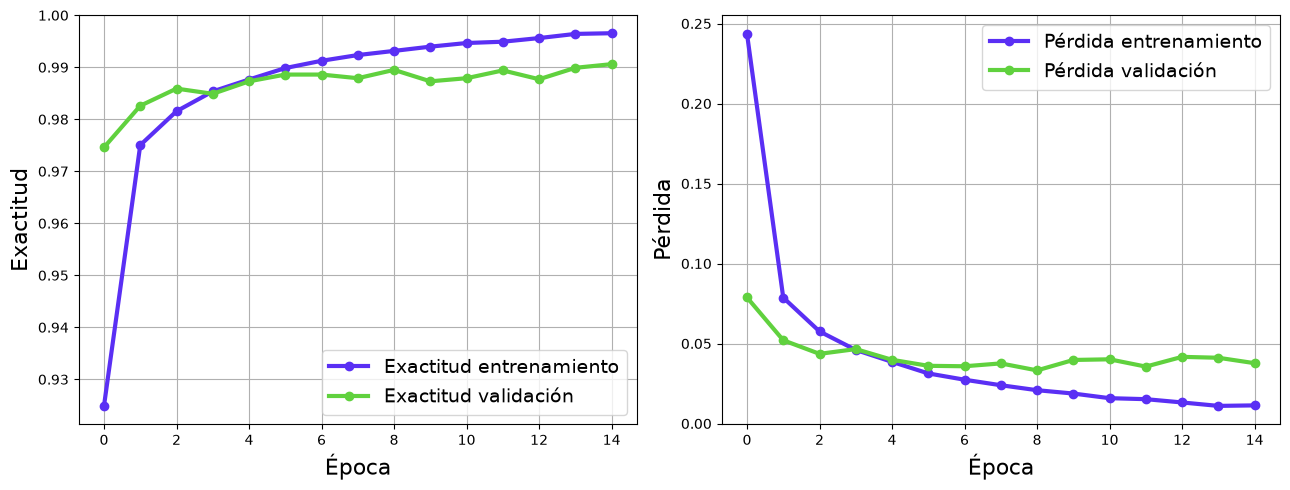

In [38]:
# Llamado a la función de visualización de las métricas del historial de entrenamiento
# del modelo; en la primera gráfica se presenta la exactitud y en la segunda la pérdida

visualizar_historial(resultsFit)

In [41]:
# Evaluación del modelo en el conjunto de prueba
modelo.eval()
with torch.no_grad():
    salidas_test = modelo(X_test.to(device))
    perdida_test = criterio(salidas_test, y_test.to(device)).item()
    exactitud_test = exactitud(salidas_test, y_test.to(device))

results = [perdida_test, exactitud_test]

# Los resultados contienen los valores de las métricas definidas: pérdida y exactitud.
print(f'Pérdida en el conjunto de prueba: {results[0]:0.2f}')
print(f'Precisión en el conjunto de prueba:{results[1]:0.2f}')

Pérdida en el conjunto de prueba: 0.04
Precisión en el conjunto de prueba:0.99


**Para finalizar el laboratorio y verificar que llegaste hasta el final reporta el valor alcanzado por el modelo en la precisión con el conjunto de prueba, usa solo dos decimales. Este valor debe quedar en la variable accTest, por favor no renombres la variable.**

In [42]:
# your code here
accTest = 0.99

In [ ]:
# Verificación automática del resultado reportado en accTest
